
Q1 - Top 10 Genres


,Genre,TotalTracks
0,Rock,1297
1,Latin,579
2,Metal,374
3,Alternative & Punk,332
4,Jazz,130
5,TV Shows,93
6,Blues,81
7,Classical,74
8,Drama,64
9,R&B/Soul,61



Q2 - Top 10 Albums


,Album,Artist,TotalTracks
0,Greatest Hits,Lenny Kravitz,57
1,Minha Historia,Chico Buarque,34
2,Unplugged,Eric Clapton,30
3,"Lost, Season 3",Lost,26
4,"Lost, Season 1",Lost,25
5,"The Office, Season 3",The Office,25
6,My Way: The Best Of Frank Sinatra [Disc 1],Frank Sinatra,24
7,"Lost, Season 2",Lost,24
8,"Battlestar Galactica (Classic), Season 1",Battlestar Galactica (Classic),24
9,Afrociberdelia,Chico Science & Nação Zumbi,23



Q3 - Top 10 Customers


...

,Track,Milliseconds,DurationMinutes
0,Occupation / Precipice,5286953,88.12
1,Through a Looking Glass,5088838,84.81
2,"Greetings from Earth, Pt. 1",2960293,49.34
3,The Man With Nine Lives,2956998,49.28
4,"Battlestar Galactica, Pt. 2",2956081,49.27
5,"Battlestar Galactica, Pt. 1",2952702,49.21
6,Murder On the Rising Star,2935894,48.93
7,"Battlestar Galactica, Pt. 3",2927802,48.80
8,Take the Celestra,2927677,48.79
9,Fire In Space,2926593,48.78



Q9 - Top 5 Artists Revenue Share


,Artist,Revenue,RevenueSharePercentage
0,Queen,190.08,4.04
1,Jimi Hendrix,185.13,3.93
2,Nirvana,128.70,2.73
3,Red Hot Chili Peppers,128.70,2.73
4,Pearl Jam,127.71,2.71



Q10 - Revenue by Country and Genre


,Country,Genre,Revenue
0,Argentina,Latin,1.98
1,Argentina,Metal,1.98
2,Argentina,Rock,10.89
3,Australia,Latin,1.98
4,Australia,Metal,13.86
...,...,...,...
65,USA,Metal,122.76
66,USA,Rock,555.39
67,United Kingdom,Latin,6.93
68,United Kingdom,Metal,30.69


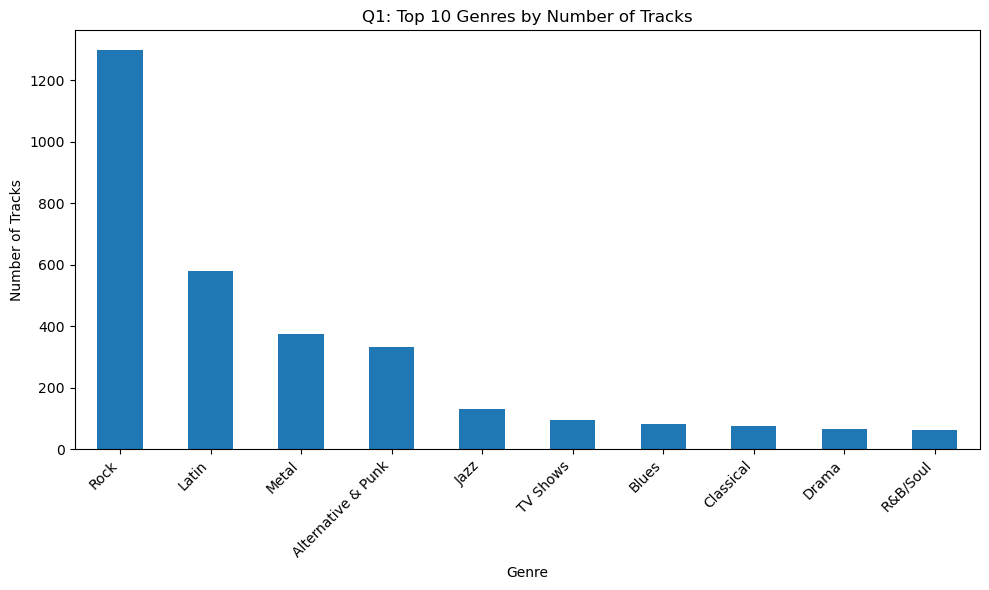

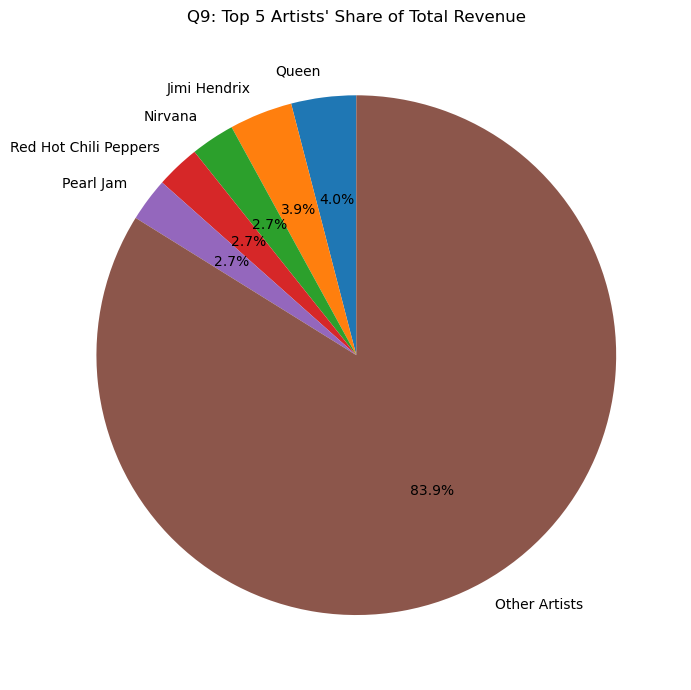

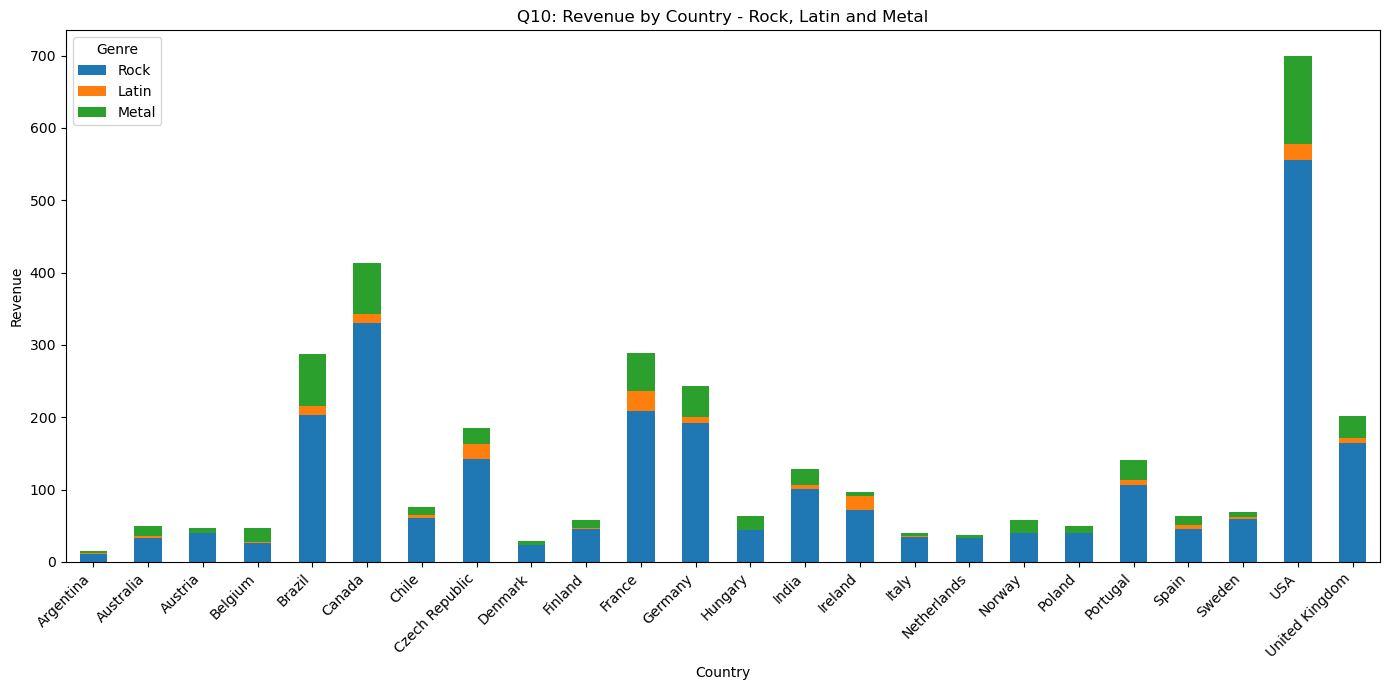


All 10 queries and available charts have completed!


In [6]:
import sqlite3
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# =========================================================
# STEP 1: CONNECT TO DATABASE
# =========================================================

conn = sqlite3.connect("Chinook.db")

def normalize(name):
    return re.sub(r"[^a-z0-9]", "", name.lower())

def quote(name):
    return '"' + name.replace('"', '""') + '"'

# Find actual table names
table_rows = conn.execute("""
    SELECT name FROM sqlite_master
    WHERE type = 'table'
""").fetchall()

table_lookup = {normalize(row[0]): row[0] for row in table_rows}

table_candidates = {
    "track": ["Track", "tracks"],
    "genre": ["Genre", "genres"],
    "album": ["Album", "albums"],
    "artist": ["Artist", "artists"],
    "customer": ["Customer", "customers"],
    "invoice": ["Invoice", "invoices"],
    "invoice_line": [
        "InvoiceLine", "invoice_line", "invoice_lines",
        "InvoiceItem", "invoice_item", "invoice_items",
        "invoice_line_items"
    ],
    "media_type": ["MediaType", "media_type", "media_types"]
}

tables = {}

for key, candidates in table_candidates.items():
    for candidate in candidates:
        actual = table_lookup.get(normalize(candidate))
        if actual:
            tables[key] = actual
            break

# These tables are necessary for the main analysis
required = [
    "track", "genre", "album", "artist",
    "customer", "invoice", "invoice_line"
]

missing = [key for key in required if key not in tables]

if missing:
    conn.close()
    raise ValueError(
        "Required tables not found: " + ", ".join(missing)
        + "\nAvailable tables: "
        + ", ".join(row[0] for row in table_rows)
        + "\nCheck that Chinook.db is the correct database file."
    )

def tbl(key):
    return quote(tables[key])

# Automatically find the actual column names
column_cache = {}

def col(table_key, *candidates):
    actual_table = tables[table_key]

    if actual_table not in column_cache:
        rows = conn.execute(
            f"PRAGMA table_info({quote(actual_table)})"
        ).fetchall()
        column_cache[actual_table] = {
            normalize(row[1]): row[1] for row in rows
        }

    lookup = column_cache[actual_table]

    for candidate in candidates:
        actual_column = lookup.get(normalize(candidate))
        if actual_column:
            return quote(actual_column)

    raise ValueError(
        f"Cannot find column {candidates} in table {actual_table}. "
        f"Available columns: {list(lookup.values())}"
    )

# =========================================================
# STEP 2: BUILD THE 10 SQL QUERIES
# =========================================================

queries = {}

# Q1: Top 10 genres by track count
queries["Q1 - Top 10 Genres"] = f"""
SELECT
    g.{col('genre', 'name')} AS Genre,
    COUNT(t.{col('track', 'track_id')}) AS TotalTracks
FROM {tbl('genre')} g
JOIN {tbl('track')} t
    ON g.{col('genre', 'genre_id')} =
       t.{col('track', 'genre_id')}
GROUP BY
    g.{col('genre', 'genre_id')},
    g.{col('genre', 'name')}
ORDER BY TotalTracks DESC
LIMIT 10;
"""

# Q2: Top 10 albums containing the most tracks
queries["Q2 - Top 10 Albums"] = f"""
SELECT
    al.{col('album', 'title')} AS Album,
    ar.{col('artist', 'name')} AS Artist,
    COUNT(t.{col('track', 'track_id')}) AS TotalTracks
FROM {tbl('album')} al
JOIN {tbl('artist')} ar
    ON al.{col('album', 'artist_id')} =
       ar.{col('artist', 'artist_id')}
JOIN {tbl('track')} t
    ON al.{col('album', 'album_id')} =
       t.{col('track', 'album_id')}
GROUP BY
    al.{col('album', 'album_id')},
    al.{col('album', 'title')},
    ar.{col('artist', 'name')}
ORDER BY TotalTracks DESC
LIMIT 10;
"""

# Q3: Top 10 customers by spending
queries["Q3 - Top 10 Customers"] = f"""
SELECT
    c.{col('customer', 'customer_id')} AS CustomerID,
    c.{col('customer', 'first_name')} || ' ' ||
    c.{col('customer', 'last_name')} AS CustomerName,
    ROUND(SUM(i.{col('invoice', 'total')}), 2) AS TotalSpent
FROM {tbl('customer')} c
JOIN {tbl('invoice')} i
    ON c.{col('customer', 'customer_id')} =
       i.{col('invoice', 'customer_id')}
GROUP BY
    c.{col('customer', 'customer_id')},
    c.{col('customer', 'first_name')},
    c.{col('customer', 'last_name')}
ORDER BY TotalSpent DESC
LIMIT 10;
"""

# Q4: Top 5 artists by track-sales revenue
queries["Q4 - Top 5 Artists by Revenue"] = f"""
SELECT
    ar.{col('artist', 'name')} AS Artist,
    ROUND(SUM(
        il.{col('invoice_line', 'unit_price')} *
        il.{col('invoice_line', 'quantity')}
    ), 2) AS Revenue
FROM {tbl('artist')} ar
JOIN {tbl('album')} al
    ON ar.{col('artist', 'artist_id')} =
       al.{col('album', 'artist_id')}
JOIN {tbl('track')} t
    ON al.{col('album', 'album_id')} =
       t.{col('track', 'album_id')}
JOIN {tbl('invoice_line')} il
    ON t.{col('track', 'track_id')} =
       il.{col('invoice_line', 'track_id')}
GROUP BY
    ar.{col('artist', 'artist_id')},
    ar.{col('artist', 'name')}
ORDER BY Revenue DESC
LIMIT 5;
"""

# Q5: Average revenue per invoice by country
queries["Q5 - Average Revenue by Country"] = f"""
SELECT
    i.{col('invoice', 'billing_country')} AS Country,
    COUNT(i.{col('invoice', 'invoice_id')}) AS TotalInvoices,
    ROUND(AVG(i.{col('invoice', 'total')}), 2)
        AS AverageRevenuePerInvoice,
    ROUND(SUM(i.{col('invoice', 'total')}), 2)
        AS TotalRevenue
FROM {tbl('invoice')} i
GROUP BY i.{col('invoice', 'billing_country')}
ORDER BY AverageRevenuePerInvoice DESC;
"""

# Q6: Number of tracks by media type
if "media_type" in tables:
    queries["Q6 - Tracks by Media Type"] = f"""
    SELECT
        m.{col('media_type', 'name')} AS MediaType,
        COUNT(t.{col('track', 'track_id')}) AS TotalTracks
    FROM {tbl('media_type')} m
    JOIN {tbl('track')} t
        ON m.{col('media_type', 'media_type_id')} =
           t.{col('track', 'media_type_id')}
    GROUP BY
        m.{col('media_type', 'media_type_id')},
        m.{col('media_type', 'name')}
    ORDER BY TotalTracks DESC;
    """
else:
    # Fallback if the database has no media type lookup table
    queries["Q6 - Tracks by Media Type"] = f"""
    SELECT
        t.{col('track', 'media_type_id')} AS MediaTypeID,
        COUNT(t.{col('track', 'track_id')}) AS TotalTracks
    FROM {tbl('track')} t
    GROUP BY t.{col('track', 'media_type_id')}
    ORDER BY TotalTracks DESC;
    """

# Q7: Artists with tracks in more than one genre
queries["Q7 - Artists with Multiple Genres"] = f"""
SELECT
    ar.{col('artist', 'name')} AS Artist,
    COUNT(DISTINCT t.{col('track', 'genre_id')}) AS TotalGenres,
    GROUP_CONCAT(DISTINCT g.{col('genre', 'name')}) AS Genres
FROM {tbl('artist')} ar
JOIN {tbl('album')} al
    ON ar.{col('artist', 'artist_id')} =
       al.{col('album', 'artist_id')}
JOIN {tbl('track')} t
    ON al.{col('album', 'album_id')} =
       t.{col('track', 'album_id')}
JOIN {tbl('genre')} g
    ON t.{col('track', 'genre_id')} =
       g.{col('genre', 'genre_id')}
GROUP BY
    ar.{col('artist', 'artist_id')},
    ar.{col('artist', 'name')}
HAVING COUNT(DISTINCT t.{col('track', 'genre_id')}) > 1
ORDER BY TotalGenres DESC, Artist;
"""

# Q8: Top 10 longest tracks
queries["Q8 - Top 10 Longest Tracks"] = f"""
SELECT
    t.{col('track', 'name')} AS Track,
    t.{col('track', 'milliseconds')} AS Milliseconds,
    ROUND(
        t.{col('track', 'milliseconds')} / 60000.0, 2
    ) AS DurationMinutes
FROM {tbl('track')} t
ORDER BY Milliseconds DESC
LIMIT 10;
"""

# Q9: Top 5 artists by share of total track-sales revenue
queries["Q9 - Top 5 Artists Revenue Share"] = f"""
WITH ArtistRevenue AS (
    SELECT
        ar.{col('artist', 'artist_id')} AS ArtistID,
        ar.{col('artist', 'name')} AS Artist,
        SUM(
            il.{col('invoice_line', 'unit_price')} *
            il.{col('invoice_line', 'quantity')}
        ) AS Revenue
    FROM {tbl('artist')} ar
    JOIN {tbl('album')} al
        ON ar.{col('artist', 'artist_id')} =
           al.{col('album', 'artist_id')}
    JOIN {tbl('track')} t
        ON al.{col('album', 'album_id')} =
           t.{col('track', 'album_id')}
    JOIN {tbl('invoice_line')} il
        ON t.{col('track', 'track_id')} =
           il.{col('invoice_line', 'track_id')}
    GROUP BY
        ar.{col('artist', 'artist_id')},
        ar.{col('artist', 'name')}
)
SELECT
    Artist,
    ROUND(Revenue, 2) AS Revenue,
    ROUND(
        Revenue * 100.0 /
        (SELECT SUM(Revenue) FROM ArtistRevenue), 2
    ) AS RevenueSharePercentage
FROM ArtistRevenue
ORDER BY Revenue DESC
LIMIT 5;
"""

# Q10: Revenue by country for Rock, Latin and Metal
queries["Q10 - Revenue by Country and Genre"] = f"""
SELECT
    i.{col('invoice', 'billing_country')} AS Country,
    g.{col('genre', 'name')} AS Genre,
    ROUND(SUM(
        il.{col('invoice_line', 'unit_price')} *
        il.{col('invoice_line', 'quantity')}
    ), 2) AS Revenue
FROM {tbl('invoice')} i
JOIN {tbl('invoice_line')} il
    ON i.{col('invoice', 'invoice_id')} =
       il.{col('invoice_line', 'invoice_id')}
JOIN {tbl('track')} t
    ON il.{col('invoice_line', 'track_id')} =
       t.{col('track', 'track_id')}
JOIN {tbl('genre')} g
    ON t.{col('track', 'genre_id')} =
       g.{col('genre', 'genre_id')}
WHERE g.{col('genre', 'name')} IN ('Rock', 'Latin', 'Metal')
GROUP BY
    i.{col('invoice', 'billing_country')},
    g.{col('genre', 'name')}
ORDER BY Country, Genre;
"""

# =========================================================
# STEP 3: RUN AND DISPLAY ALL 10 QUERIES
# =========================================================

results = {}

for title, query in queries.items():
    df = pd.read_sql_query(query, conn)
    results[title] = df

    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)
    display(df)

# =========================================================
# STEP 4: Q1 - BAR PLOT
# =========================================================

df1 = results["Q1 - Top 10 Genres"]

if not df1.empty:
    ax = df1.plot(
        kind="bar",
        x="Genre",
        y="TotalTracks",
        figsize=(10, 6),
        legend=False
    )
    ax.set_title("Q1: Top 10 Genres by Number of Tracks")
    ax.set_xlabel("Genre")
    ax.set_ylabel("Number of Tracks")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# =========================================================
# STEP 5: Q9 - PIE CHART
# =========================================================

df9 = results["Q9 - Top 5 Artists Revenue Share"]

total_revenue_query = f"""
SELECT COALESCE(
    SUM(
        il.{col('invoice_line', 'unit_price')} *
        il.{col('invoice_line', 'quantity')}
    ), 0
) AS TotalRevenue
FROM {tbl('invoice_line')} il;
"""

total_revenue = pd.read_sql_query(
    total_revenue_query, conn
)["TotalRevenue"].iloc[0]

if not df9.empty:
    top_revenue = df9["Revenue"].sum()
    other_revenue = max(0, total_revenue - top_revenue)

    labels = df9["Artist"].tolist()
    values = df9["Revenue"].tolist()

    if other_revenue > 0:
        labels.append("Other Artists")
        values.append(other_revenue)

    plt.figure(figsize=(9, 7))
    plt.pie(
        values,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90
    )
    plt.title("Q9: Top 5 Artists' Share of Total Revenue")
    plt.tight_layout()
    plt.show()

# =========================================================
# STEP 6: Q10 - STACKED COLUMN CHART
# =========================================================

df10 = results["Q10 - Revenue by Country and Genre"]

if not df10.empty:
    pivot = df10.pivot_table(
        index="Country",
        columns="Genre",
        values="Revenue",
        aggfunc="sum",
        fill_value=0
    )

    pivot = pivot.reindex(
        columns=["Rock", "Latin", "Metal"],
        fill_value=0
    )

    ax = pivot.plot(
        kind="bar",
        stacked=True,
        figsize=(14, 7)
    )

    ax.set_title("Q10: Revenue by Country - Rock, Latin and Metal")
    ax.set_xlabel("Country")
    ax.set_ylabel("Revenue")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Genre")
    plt.tight_layout()
    plt.show()
else:
    print("Q10: No revenue records found for Rock, Latin or Metal.")

# =========================================================
# STEP 7: FINISH
# =========================================================

conn.close()
print("\nAll 10 queries and available charts have completed!")